# Lord of the Rings NLP Refactor
This notebook compares classic topic models and embedding-based topic modeling for Tolkien's trilogy.
It uses chapter-level documents and includes coherence scoring plus timeline visualization.


In [1]:
from pathlib import Path
import importlib
import lotr_nlp
importlib.reload(lotr_nlp)

try:
    lotr_nlp.ensure_nltk_resources()
except Exception as exc:
    print("Warning: NLTK resources could not be downloaded automatically.")
    print("If needed, install them manually with:")
    print("  python3 -m nltk.downloader punkt wordnet omw-1.4 stopwords")
    print(exc)

BOOK_DIR = Path.cwd() / "the_lord_of_the_rings_text"
print("Notebook cwd:", Path.cwd())
print("Book dir exists:", BOOK_DIR.exists())
print("Book files:", sorted([p.name for p in BOOK_DIR.glob('the_*.txt')]))

book_texts = lotr_nlp.load_book_texts(BOOK_DIR)
print("Loaded books:")
for book_name, _ in book_texts:
    print(f"- {book_name}")

chapter_docs = lotr_nlp.build_book_chapter_documents(
    BOOK_DIR,
    preserve_case=False,
    extra_stopwords=["said", "come", "came"],
)
print(f"Built {len(chapter_docs)} chapter documents across the trilogy")


INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloadin

Notebook cwd: /Users/jdhazard/Desktop/refactored_LoTR_project/tolkien_nlp_capstone
Book dir exists: True
Book files: ['the_fellowship_of_the_ring.txt', 'the_return_of_king.txt', 'the_two_towers.txt']
Loaded books:
- Fellowship Of Ring
- Return Of King
- Two Towers


INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloading NLTK resource: wordnet
INFO: Downloading NLTK resource: omw-1.4
INFO: Downloadin

Built 66 chapter documents across the trilogy


## Chapter-level LDA
Fit LDA on chapter documents, show top topic terms, compute coherence, and plot topic prevalence across the trilogy timeline.


INFO: adding document #0 to Dictionary<0 unique tokens: []>
INFO: built Dictionary<12595 unique tokens: ['1147', '1158', '2', '37', '60']...> from 66 documents (total 221353 corpus positions)
INFO: Dictionary lifecycle event {'msg': "built Dictionary<12595 unique tokens: ['1147', '1158', '2', '37', '60']...> from 66 documents (total 221353 corpus positions)", 'datetime': '2026-09-24T16:08:26.241582', 'gensim': '4.4.0', 'python': '3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:13:42) [Clang 20.1.8 ]', 'platform': 'macOS-26.6.2-arm64-arm-64bit-Mach-O', 'event': 'created'}
INFO: using ParallelWordOccurrenceAccumulator<processes=9, batch_size=64> to estimate probabilities from sliding windows


LDA topic terms:
Topic 1: aragorn gandalf men frodo sam lord gimli legolas stood hope shall looked trees fell wind
Topic 2: frodo sam gandalf hobbits aragorn night men looked shall stood good trees hand pippin legolas
Topic 3: frodo sam gandalf ring men shall pippin bilbo hand stood master gollum looked right hobbits
Topic 4: frodo sam gandalf men aragorn pippin shall looked merry hobbits road night good hand stood
Topic 5: frodo sam gollum gandalf merry master hobbits pippin shall trees faramir men water hand lay
Topic 6: sam frodo gandalf pippin shall men looked aragorn lord hobbits king road night hand man
Topic 7: frodo men aragorn shall sam gandalf looked faramir road gimli let merry good king master
Topic 8: frodo gandalf gimli pippin sam stood looked aragorn hobbits night road shall deep merry hand
Topic 9: gandalf sam frodo pippin road men merry looked aragorn ring mr going night stood let
Topic 10: frodo sam gandalf pippin men shall aragorn merry road hobbits hand night cried 

INFO: 1 batches submitted to accumulate stats from 64 documents (208705 virtual)
INFO: 2 batches submitted to accumulate stats from 128 documents (214159 virtual)
INFO: 9 accumulators retrieved from output queue
INFO: accumulated word occurrence stats for 214159 virtual documents



LDA coherence (c_v): 0.2721


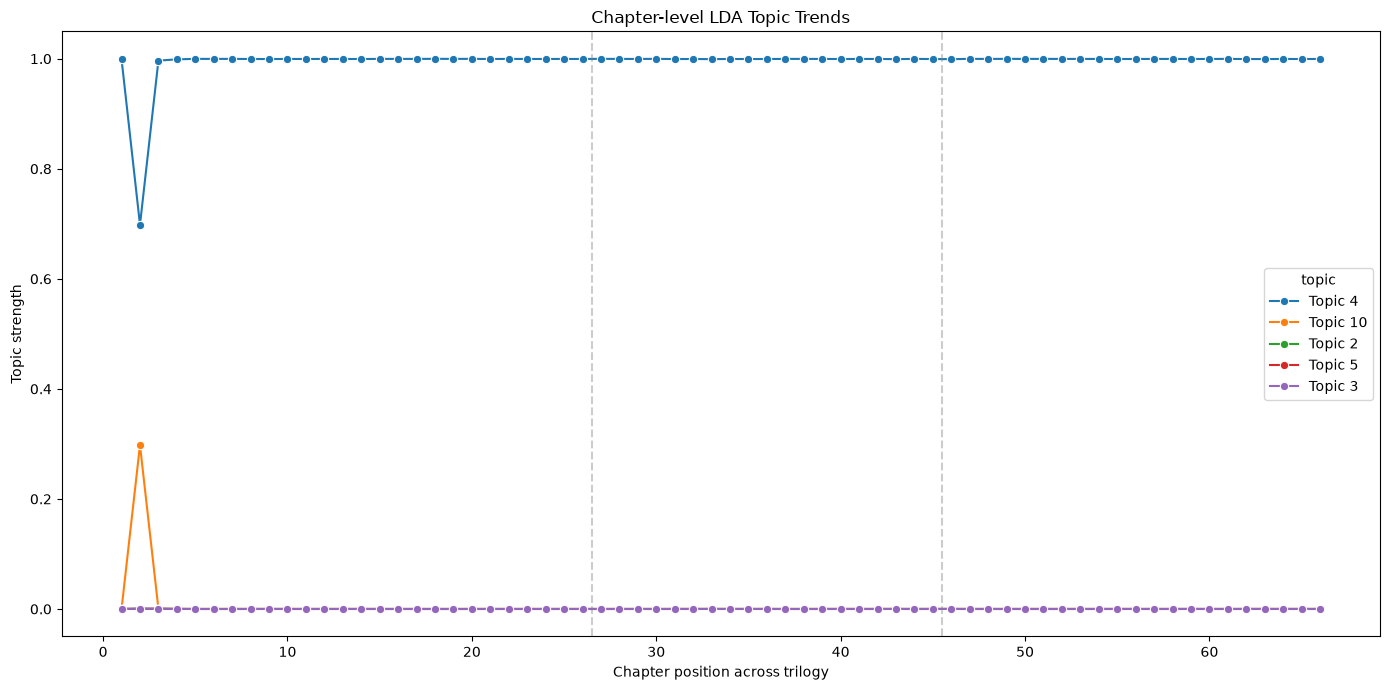

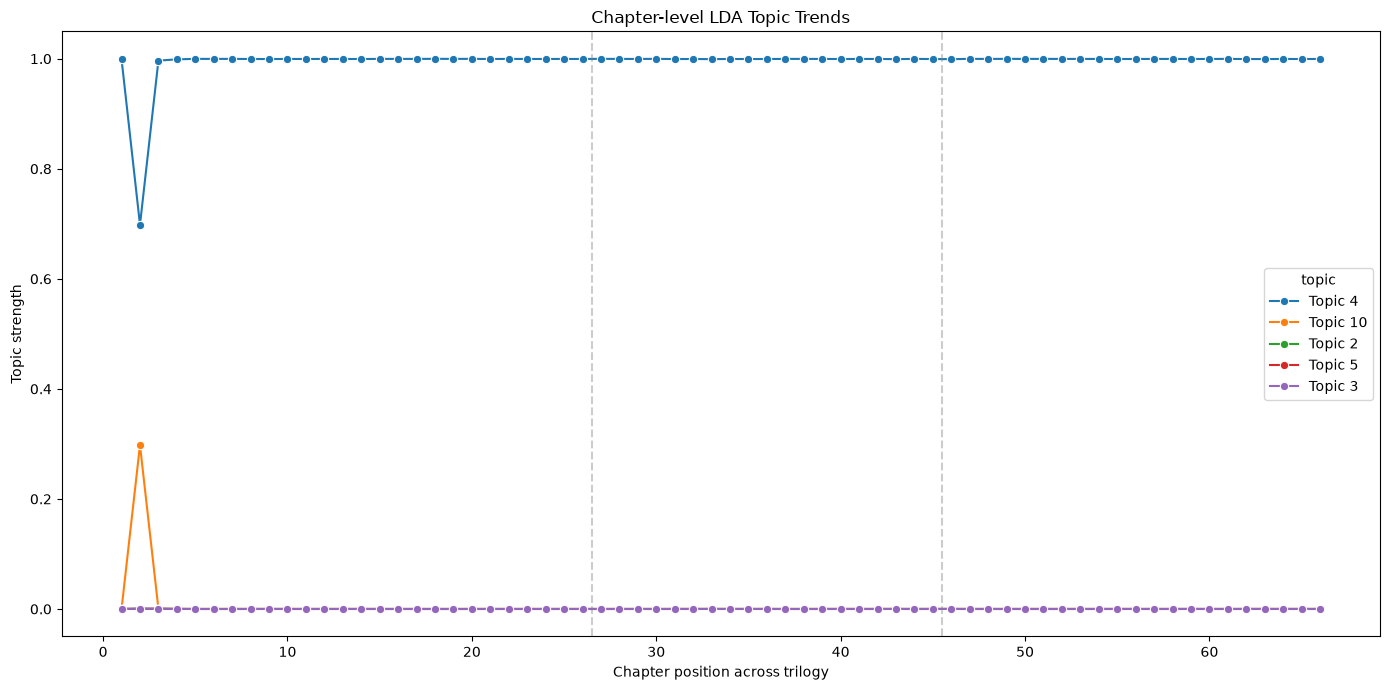

In [2]:
from sklearn.feature_extraction.text import CountVectorizer

documents = [chapter['document'] for chapter in chapter_docs]
tokenized_documents = [chapter['tokens'] for chapter in chapter_docs]

lda_vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
lda_matrix = lda_vectorizer.fit_transform(documents)
lda_model = lotr_nlp.fit_lda(lda_matrix, n_components=10)
lda_terms = lotr_nlp.get_topic_term_lists(lda_model, lda_vectorizer.get_feature_names_out(), 15)

print("LDA topic terms:")
lotr_nlp.print_top_words(lda_model, lda_vectorizer.get_feature_names_out(), n_top_words=15)
print(f"\nLDA coherence (c_v): {lotr_nlp.compute_coherence(lda_terms, tokenized_documents):.4f}")

lda_fig = lotr_nlp.plot_topic_trends(
    lda_model.transform(lda_matrix),
    chapter_docs,
    top_n=5,
    title="Chapter-level LDA Topic Trends",
)
lda_fig


## TF-IDF + NMF
Fit NMF on TF-IDF chapter documents, print topic terms, compute coherence, and plot topic series.


INFO: adding document #0 to Dictionary<0 unique tokens: []>
INFO: built Dictionary<12595 unique tokens: ['1147', '1158', '2', '37', '60']...> from 66 documents (total 221353 corpus positions)
INFO: Dictionary lifecycle event {'msg': "built Dictionary<12595 unique tokens: ['1147', '1158', '2', '37', '60']...> from 66 documents (total 221353 corpus positions)", 'datetime': '2026-09-24T16:11:27.657952', 'gensim': '4.4.0', 'python': '3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:13:42) [Clang 20.1.8 ]', 'platform': 'macOS-26.6.2-arm64-arm-64bit-Mach-O', 'event': 'created'}
INFO: using ParallelWordOccurrenceAccumulator<processes=9, batch_size=64> to estimate probabilities from sliding windows


NMF topic terms:
Topic 1: gollum smjagol frodo sam yes precious nice faramir master hobbits rope fish men night good
Topic 2: jomer king thjoden men jowyn aragorn merry lord ride shall rode legolas man riders ghvn
Topic 3: sam frodo mr shagrat ore shelob hand gorbag got going road tower ores mountain master
Topic 4: faramir denethor pippin gandalf city beregond men lord citadel gondor boromir mithrandir gate shall stood
Topic 5: treebeard saruman ents gandalf pippin isengard orthanc gimli ent merry legolas thjoden trees hm fangorn
Topic 6: frodo bilbo gandalf ring shire bag elrond birthday baggins good pippin sackville bagginses elves hall
Topic 7: aragorn gimli legolas boromir frodo boats boat ores company river gandalf haldir shall night elves
Topic 8: tom goldberry merry frodo forest willow ponies hobbits trees bombadil pippin hill water path looked
Topic 9: strider butterbur bree frodo nob mr gandalf road landlord ferny barliman merry sam underhill pippin
Topic 10: hobbits shire fa

INFO: 1 batches submitted to accumulate stats from 64 documents (208705 virtual)
INFO: 2 batches submitted to accumulate stats from 128 documents (214159 virtual)
INFO: 9 accumulators retrieved from output queue
INFO: accumulated word occurrence stats for 214159 virtual documents



NMF coherence (c_v): 0.5392


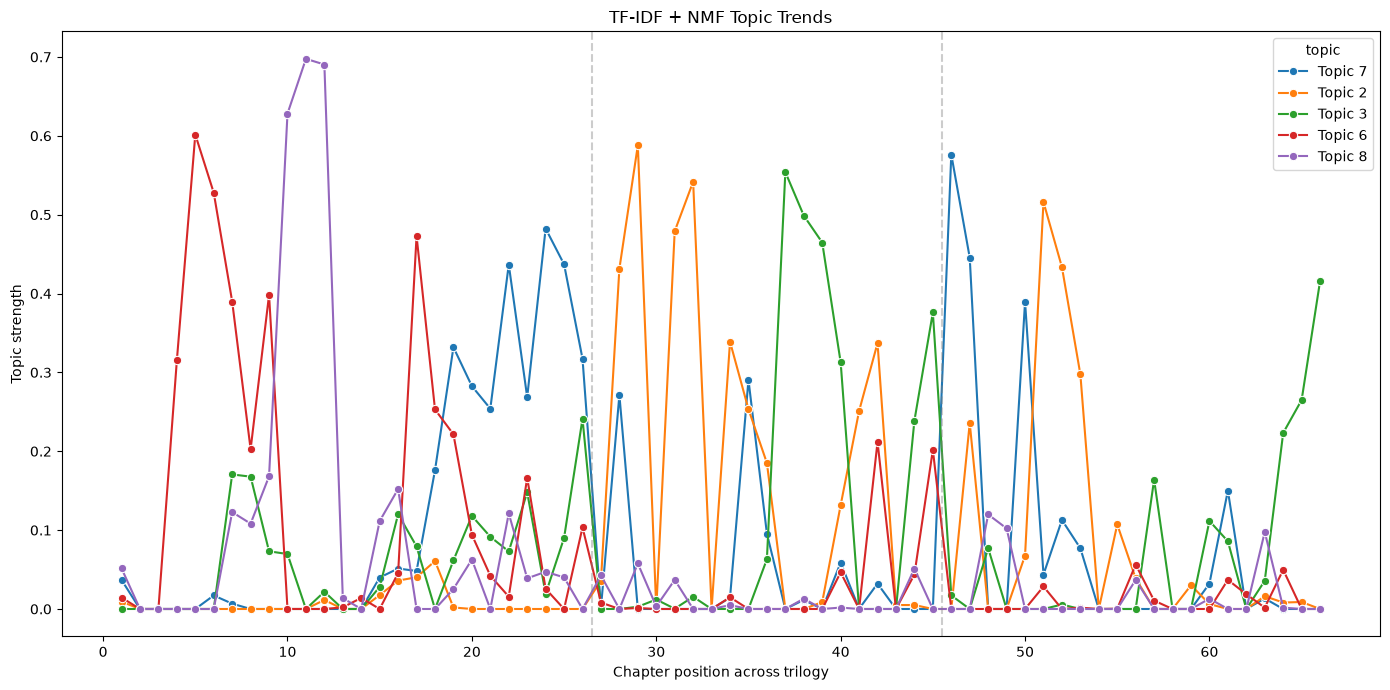

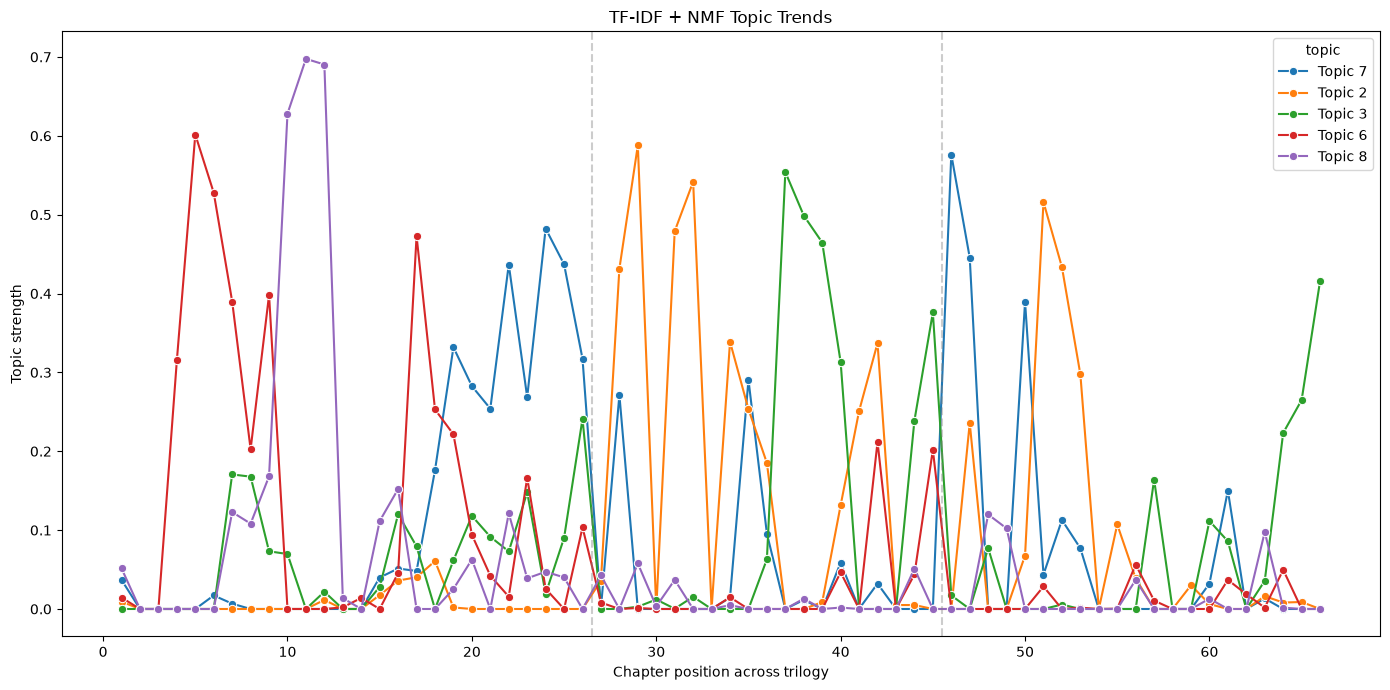

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
tfidf_matrix = tfidf_vectorizer.fit_transform(documents)
nmf_model = lotr_nlp.fit_nmf(tfidf_matrix, n_components=10)
nmf_terms = lotr_nlp.get_topic_term_lists(nmf_model, tfidf_vectorizer.get_feature_names_out(), 15)

print("NMF topic terms:")
lotr_nlp.print_top_words(nmf_model, tfidf_vectorizer.get_feature_names_out(), n_top_words=15)
print(f"\nNMF coherence (c_v): {lotr_nlp.compute_coherence(nmf_terms, tokenized_documents):.4f}")

nmf_fig = lotr_nlp.plot_topic_trends(
    nmf_model.transform(tfidf_matrix),
    chapter_docs,
    top_n=5,
    title="TF-IDF + NMF Topic Trends",
)
nmf_fig


## Embedding-based Topic Modeling
Cluster chapter embeddings with KMeans, extract top cluster terms, and score coherence.


In [ ]:
import importlib

if "lotr_nlp" not in globals():
    import lotr_nlp
    importlib.reload(lotr_nlp)

if "chapter_docs" not in globals():
    raise NameError("chapter_docs is not defined. Run the chapter-loading cell before embedding-based modeling.")

documents = [chapter["document"] for chapter in chapter_docs]
tokenized_documents = [chapter["tokens"] for chapter in chapter_docs]

labels, embeddings, embedding_model = lotr_nlp.fit_embedding_topic_model(documents, n_clusters=10)
cluster_topics = lotr_nlp.get_cluster_topic_terms(documents, labels, n_top_words=15)

print("Embedding-based clusters:")
for label, terms in cluster_topics:
    print(f"Cluster {label}: {' '.join(terms)}")

print(f"\nEmbedding coherence (c_v): {lotr_nlp.compute_coherence([terms for _, terms in cluster_topics], tokenized_documents):.4f}")


INFO: No device provided, using mps
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/config_sentence_transformers.json "HTTP/1.1 200 OK"
INFO: Loading SentenceTransformer model from sentence-transformers/all-MiniLM-L6-v2.
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config_sentence_transformers.json "HTTP/1.1 307 Temporary Redirect"
INFO: H

README.md: 0.00B [00:00, ?B/s]

INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/modules.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/modules.json "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/sentence_bert_config.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/sentence_bert_config.json "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/adapter_config.json "HTTP/1.1 404 Not Found"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: H

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/processor_config.json "HTTP/1.1 404 Not Found"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/video_preprocessor_config.json "HTTP/1.1 404 Not Found"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/preprocessor_config.json "HTTP/1.1 404 Not Found"
INFO: HTTP Request: HEAD https://huggingface.co/sentence-transformers/all-MiniLM-L6-v2/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
INFO: HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/sentence-transformers/all-MiniLM-L6-v2/1110a243fdf4706b3f48f1d95db1a4f5529b4d41/tokenizer_config.json "HTTP/1.1 200 OK"
INFO: HTTP Request: HEAD https://huggingface.co/

## Timeline Summary
The two timeline plots show how the strongest topics evolve across the trilogy, using chapter order as the narrative timeline.


In [ ]:
print("LDA timeline plot:")
lda_fig

print("NMF timeline plot:")
nmf_fig


## Notes
- The chapter-level models use the three individual trilogy files rather than a single monolithic text.
- Embedding-based clustering is a semantic complement to the bag-of-words methods.
- Coherence scores help compare model interpretability across approaches.
